# Robot BOM — Mistral API + Grounding DINO + SAM 2

**Live Mistral API notebook** for the supplied RC robot. Pipeline: Mistral image inspection → DINO localization → SAM 2 segmentation → Mistral per-part inspection → Mistral mechanical reasoning → Mistral evidence reconciliation → deterministic BOM checks.

**No API/model inference has been executed during creation.** Estimated reference boxes and actual detector results are clearly separated. Mistral confidence is not calibrated; exact SKUs cannot be confirmed from a single photograph.

## Setup

Install with `uv pip install notebook ipykernel mistralai truststore python-dotenv pydantic numpy pandas pillow matplotlib opencv-python torch torchvision "transformers==4.51.3" huggingface_hub` and `uv pip install git+https://github.com/facebookresearch/sam2.git` (for SAM 2).

The setup cell loads the nearest `.env` walking up from this notebook's folder, so the repo-root `.env` (`MISTRAL_API_KEY=...`, optionally `MISTRAL_MODEL=mistral-large-4`) is used; a `.env` beside the notebook would take precedence. Do not upload or commit `.env`. First launch may download large model weights. Grounding DINO/SAM 2 are GPU-intensive; skip their cells if unavailable, and continue with Mistral reference-box crops.

Mistral model: mistral-large-4 | key loaded from: E:\sourcecode\mistral-build-a-bot\.env | image: 480 640


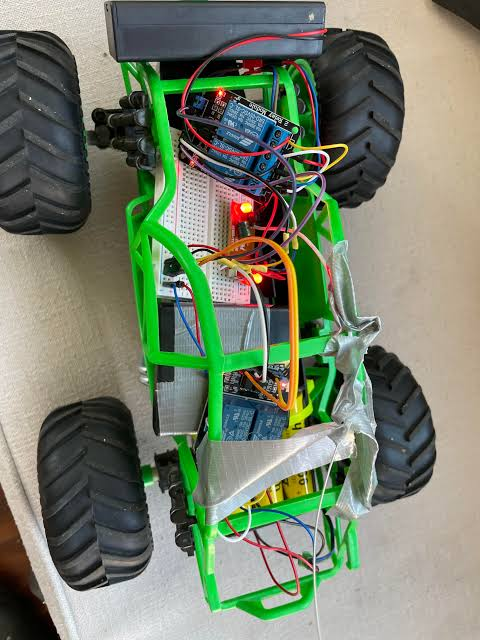

In [15]:
from pathlib import Path
import os, json, base64, io, re, time
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from dotenv import load_dotenv
try:
    from mistralai.client import Mistral  # mistralai >= 2 (installed: 3.8)
except ImportError:
    from mistralai import Mistral  # mistralai 1.x
# Verify TLS against the OS certificate store. Needed behind antivirus / corporate TLS
# inspection, otherwise the Hugging Face weight downloads fail with CERTIFICATE_VERIFY_FAILED.
try:
    import truststore; truststore.inject_into_ssl()
except ImportError:
    pass

# Folder holding this notebook, wherever the kernel was started from.
NB_NAME='robot_mistral_dino_sam2.ipynb'
NB_DIR=next((d for d in [Path.cwd(),Path.cwd()/'test-mistral'] if (d/NB_NAME).is_file()),Path.cwd()).resolve()
# Nearest .env walking up from the notebook folder (this finds the repo-root .env).
ENV_FILE=next((d/'.env' for d in [NB_DIR,*NB_DIR.parents] if (d/'.env').is_file()),None)
load_dotenv(ENV_FILE)
# Keep the ~850 MB of Grounding DINO / SAM 2 weights next to the project instead of the default
# cache in the user profile on C:, which has no free space. An HF_HOME set elsewhere wins.
os.environ.setdefault('HF_HOME',str(NB_DIR.parent/'.hf-cache'))
IMAGE_PATH=NB_DIR/'robot_reference.png'
OUT=NB_DIR/'mistral_robot_results'; OUT.mkdir(exist_ok=True)
OUTPUT_DIR=OUT # compatibility with local detection cells
RUN_LOCAL_DETECTION=True # set False to run Mistral-only workflow
image=Image.open(IMAGE_PATH).convert('RGB'); W,H=image.size
MODEL=(os.getenv('MISTRAL_MODEL') or 'mistral-large-4').strip()
KEY=(os.getenv('MISTRAL_API_KEY') or '').strip()
if not KEY: raise RuntimeError(f'MISTRAL_API_KEY is not set. .env file used: {ENV_FILE} (searched upward from {NB_DIR}).')
client=Mistral(api_key=KEY)
print('Mistral model:',MODEL,'| key loaded from:',ENV_FILE,'| image:',W,H)
display(image)

def as_uri(im):
    x=im.copy(); x.thumbnail((1400,1400)); f=io.BytesIO(); x.save(f,'JPEG',quality=90)
    return 'data:image/jpeg;base64,'+base64.b64encode(f.getvalue()).decode()
def as_json(value):
    if isinstance(value,list): value='\n'.join((v.get('text','') if isinstance(v,dict) else getattr(v,'text','')) for v in value)
    value=re.sub(r'^\s*```(?:json)?\s*|\s*```\s*$','',str(value).strip(),flags=re.I)
    try:return json.loads(value)
    except json.JSONDecodeError:
        pos=min((p for p in [value.find('{'),value.find('[')] if p>=0),default=-1)
        if pos<0:raise
        return json.JSONDecoder().raw_decode(value[pos:])[0]
def ask_mistral(prompt,images=None,filename=None):
    content=[{'type':'text','text':prompt}]+[{'type':'image_url','image_url':as_uri(im)} for im in (images or [])]
    answer=client.chat.complete(model=MODEL,messages=[{'role':'user','content':content}],temperature=0,top_p=1)
    raw=answer.choices[0].message.content
    obj=as_json(raw)
    if filename:(OUT/filename).write_text(json.dumps({'model':MODEL,'result':obj},indent=2))
    return obj


## 1 · Mistral call 1: identify components, positions and uncertain parts

This makes a **real** Mistral vision API call on the original photo. Each visible instance gets a unique ID and proposed bounding box. If your account does not expose `mistral-large-4`, change `MISTRAL_MODEL` to an available vision-capable model.

In [16]:
prompt=f'''Inspect this {W}x{H} robot photo. Reply ONLY with JSON object: {{"parts":[{{"id":"V001","category":"wheel","description":"...","box_xyxy":[x1,y1,x2,y2],"evidence":"visible","confidence":0.8,"exact_sku":null}}],"uncertainties":["..."]}}. Record EACH separate visible object (4 wheels must be 4 instances). Pixel coordinates refer to ORIGINAL image dimensions. Include frame/chassis, wiring, breadboard, modules, battery/power enclosure. Never invent hidden motor specifications, manufacturer, quantities, or SKU. Confidence is subjective, not calibrated. Include only visible objects in parts.'''
initial=ask_mistral(prompt,[image],'01_initial_inventory.json')
assert isinstance(initial.get('parts'),list),'Mistral response missing parts[]'
display(pd.DataFrame(initial['parts']))
print('Uncertainties:',initial.get('uncertainties',[]))

,id,category,description,box_xyxy,evidence,confidence,exact_sku
0,W001,wheel,"large black treaded wheel at top-left, partly ...","[0, 31, 91, 244]",visible,0.95,None
1,W002,wheel,large black treaded wheel at top-right,"[313, 31, 407, 224]",visible,0.95,None
2,W003,wheel,large black treaded wheel at bottom-left,"[39, 407, 153, 620]",visible,0.95,None
3,W004,wheel,large black treaded wheel at bottom-right,"[363, 354, 438, 535]",visible,0.95,None
4,C001,frame/chassis,bright green tubular plastic frame/chassis hol...,"[124, 58, 365, 632]",visible,0.90,None
5,P001,battery/power enclosure,black rectangular power/battery enclosure acro...,"[104, 0, 318, 64]",visible,0.85,None
6,B001,breadboard,white solderless breadboard in the center with...,"[151, 174, 263, 326]",visible,0.90,None
7,M001,module,upper blue PCB module near the top with a lit ...,"[181, 99, 303, 207]",visible,0.75,None
8,M002,module,"lower blue PCB module near bottom-center, part...","[220, 386, 303, 493]",visible,0.70,None
9,O001,other,gray rectangular metal-looking block beneath t...,"[157, 306, 291, 459]",visible,0.55,None


Uncertainties: ['Exact functions, manufacturers, and SKUs of the blue PCB modules are not legible; they may be relay/driver/controller boards but this is not confirmed.', 'Individual wire endpoints are obscured by tape, the breadboard, and overlapping modules.', 'Wheel hubs, axles, and any motors are mostly hidden; no motor specifications, quantities, or ratings are inferred.', 'Contents of the black top enclosure are not visible, so battery count, chemistry, and capacity are unknown.', 'The gray rectangular block could be a heatsink, shield, or enclosure; its purpose is uncertain.', 'The silver tape appears to be holding the front/right assembly, but the exact secured part is not fully visible.']


## 1 — What is visible? Component-by-component inventory

This is a **reference inventory for human review**, not an exact reconstruction. There are four visible rubber wheels, a green structural frame, a small white breadboard, multiple wires, two visible blue electronic board assemblies, red indicator lights and a black upper enclosure. The exact models, electrical ratings and hidden drivetrain are unknown. The blue boards appear relay-like, but their identities must be checked with close-up images or board markings.

A wheel can be detected without proving there is a motor behind it. Similarly, a black enclosure is not automatically a confirmed battery pack.

| Reference ID | Component | Visible count | Caution |
|---|---|---:|---|
| W1–W4 | Wheels/tyres | 4 | Motor coupling and hubs not confirmed |
| CH | Green chassis/frame | 1 assembly | Custom/fabricated geometry possible |
| PWR | Black upper enclosure | 1 | Contents unknown |
| PCB1, PCB2 | Blue electronic PCB/module assemblies | 2 apparent | Exact board type needs inspection |
| BB | Breadboard | 1 | Electrical connections not fully readable |
| WIR | Jumper wires | multiple | Exact count/length cannot be determined |
| LED | Illuminated indicators | at least 2 | Some lights could be board indicators |
| TAPE | Silver mounting tape | visible | May be temporary retention, not a designed fastener |
| MOTORS | Motors, axle couplings, hidden fasteners | unknown | Do **not** label as visually confirmed |


## 2 — Inspect EACH component using reference boxes

The reference boxes below were estimated manually from the uploaded image for demonstration. They help you examine the image one component at a time and establish a baseline. They are **not Grounding DINO detections** and are not pixel-precise masks.

Select a reference ID below to view the crop. Real model detections in Sections 4–5 will replace these manual locations.

Reference IDs: W1, W2, W3, W4, CH, PWR, PCB1, BB, PCB2, WIR, LED, TAPE


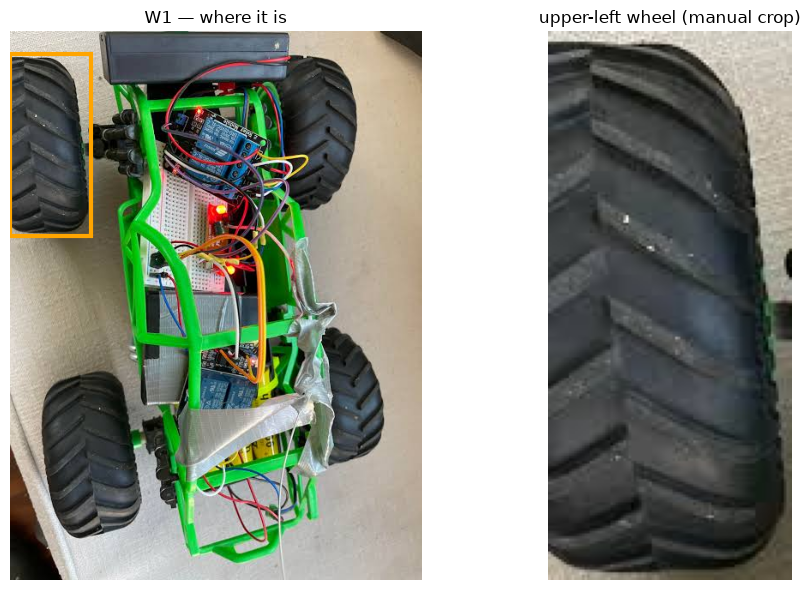

Evidence: visible


In [17]:
# Coordinates in original image (480 x 640), XYXY, manually estimated.
reference_parts = [
    {"id":"W1", "name":"upper-left wheel", "category":"wheel", "bbox":[0,26,94,238], "evidence":"visible"},
    {"id":"W2", "name":"upper-right wheel", "category":"wheel", "bbox":[313,28,411,220], "evidence":"visible"},
    {"id":"W3", "name":"lower-left wheel", "category":"wheel", "bbox":[32,394,153,612], "evidence":"visible"},
    {"id":"W4", "name":"lower-right wheel", "category":"wheel", "bbox":[348,338,468,518], "evidence":"visible"},
    {"id":"CH", "name":"green chassis", "category":"chassis", "bbox":[113,54,373,612], "evidence":"visible"},
    {"id":"PWR", "name":"black upper enclosure", "category":"enclosure", "bbox":[100,0,329,67], "evidence":"visible; internal contents unknown"},
    {"id":"PCB1", "name":"upper blue PCB/module", "category":"electronic_module", "bbox":[174,73,314,180], "evidence":"visible; exact identity unverified"},
    {"id":"BB", "name":"white solderless breadboard", "category":"breadboard", "bbox":[162,157,299,316], "evidence":"visible"},
    {"id":"PCB2", "name":"lower blue PCB/module", "category":"electronic_module", "bbox":[187,307,319,457], "evidence":"visible; exact identity unverified"},
    {"id":"WIR", "name":"wire bundle", "category":"wiring", "bbox":[172,122,360,382], "evidence":"visible; count not reliable"},
    {"id":"LED", "name":"red illuminated indicators area", "category":"indicator", "bbox":[224,190,275,290], "evidence":"visible; at least two lights"},
    {"id":"TAPE", "name":"silver securing tape", "category":"mounting_tape", "bbox":[215,340,369,526], "evidence":"visible"},
]

def show_reference(part_id):
    item = next(x for x in reference_parts if x["id"] == part_id)
    x1,y1,x2,y2 = item["bbox"]
    fig, axes = plt.subplots(1,2,figsize=(10,6))
    axes[0].imshow(image)
    axes[0].add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='orange',linewidth=3))
    axes[0].set_title(f"{part_id} — where it is")
    axes[1].imshow(image.crop((x1,y1,x2,y2)))
    axes[1].set_title(f"{item['name']} (manual crop)")
    for a in axes: a.axis('off')
    plt.tight_layout(); plt.show()
    print('Evidence:',item['evidence'])

print('Reference IDs:', ', '.join(p['id'] for p in reference_parts))
show_reference('W1')

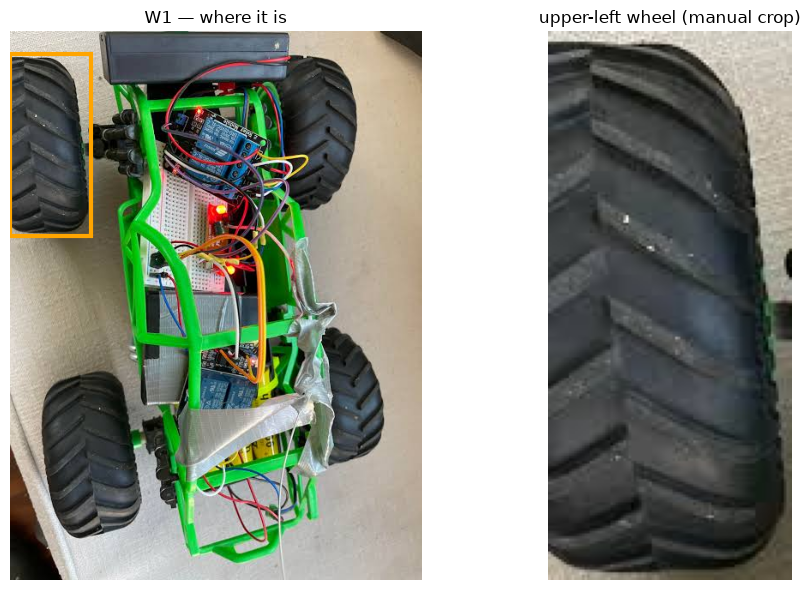

Evidence: visible


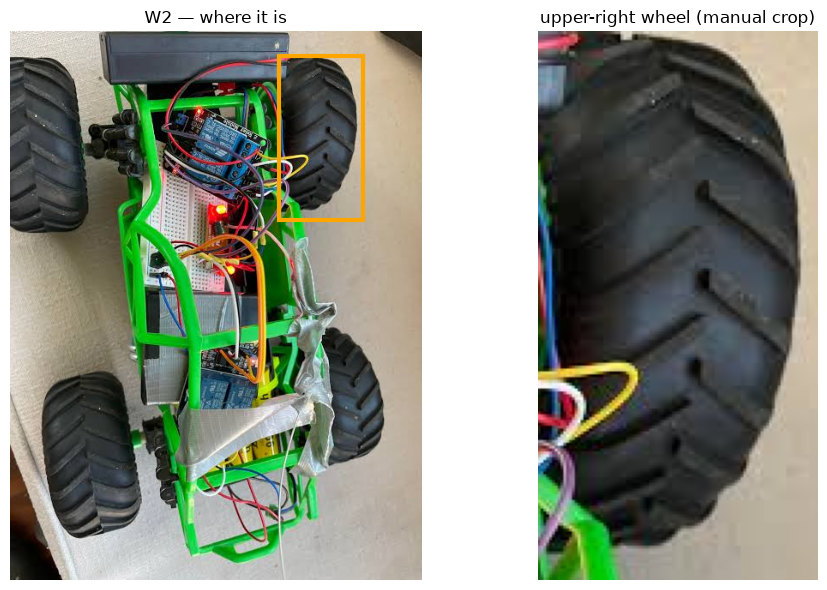

Evidence: visible


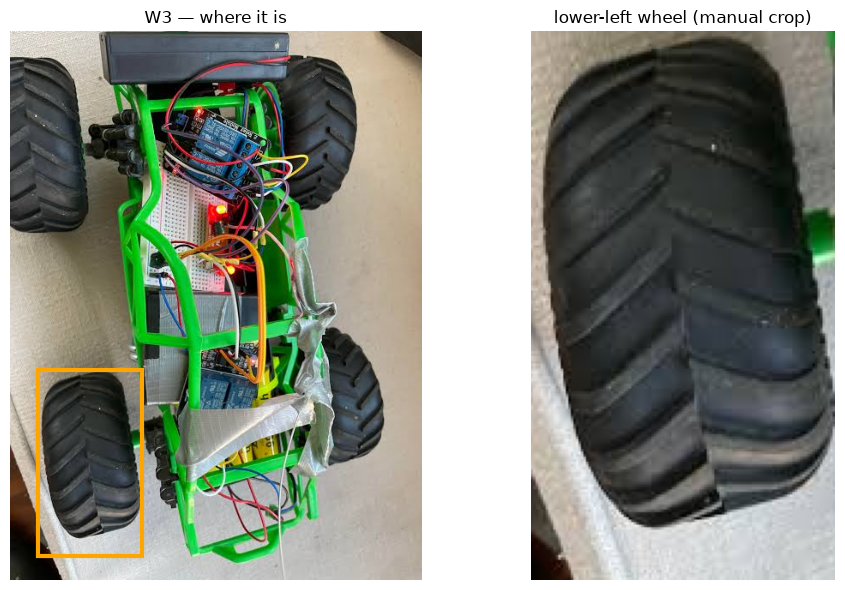

Evidence: visible


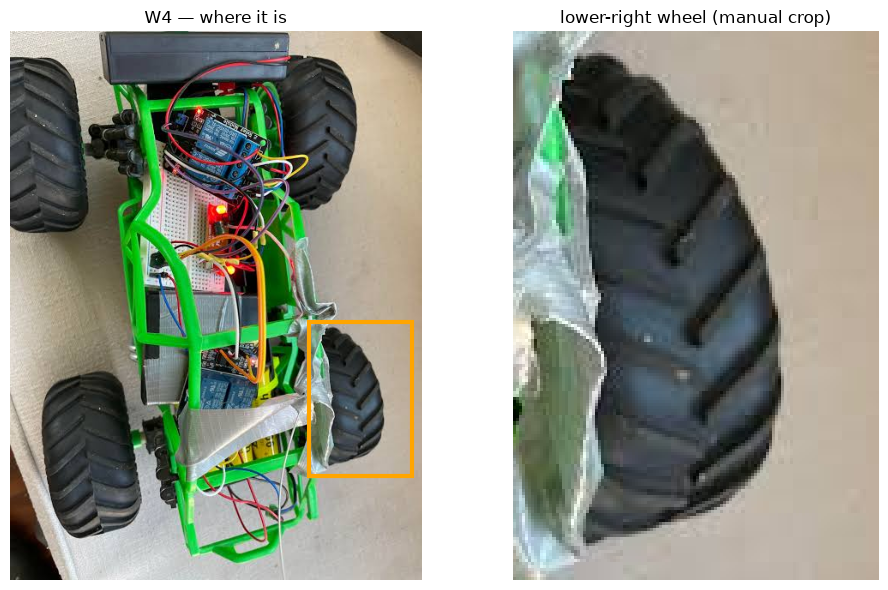

Evidence: visible


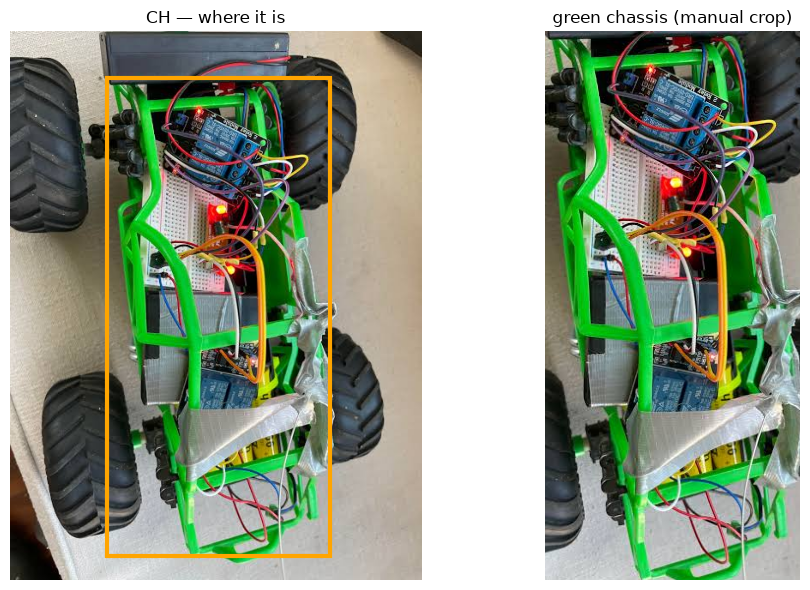

Evidence: visible


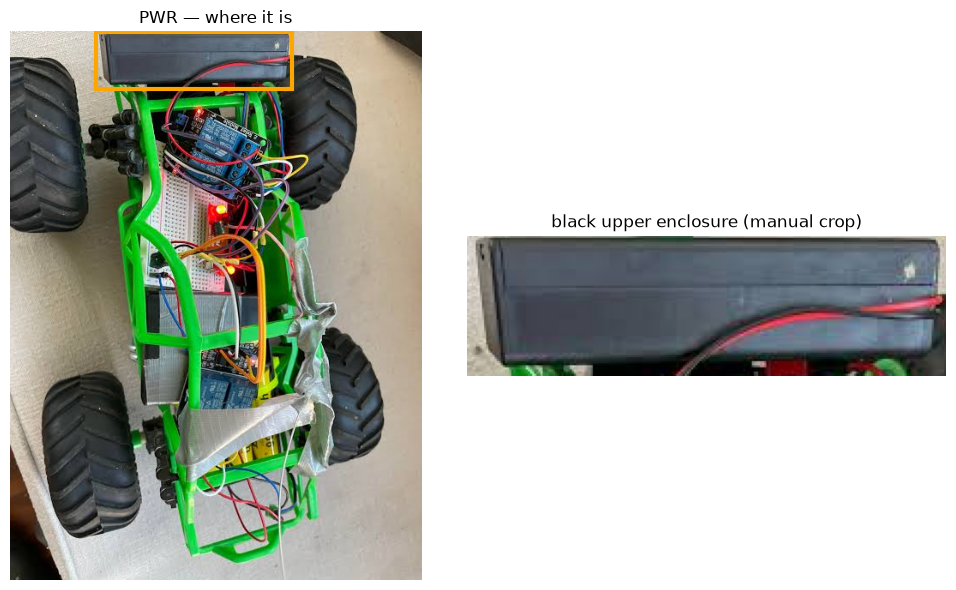

Evidence: visible; internal contents unknown


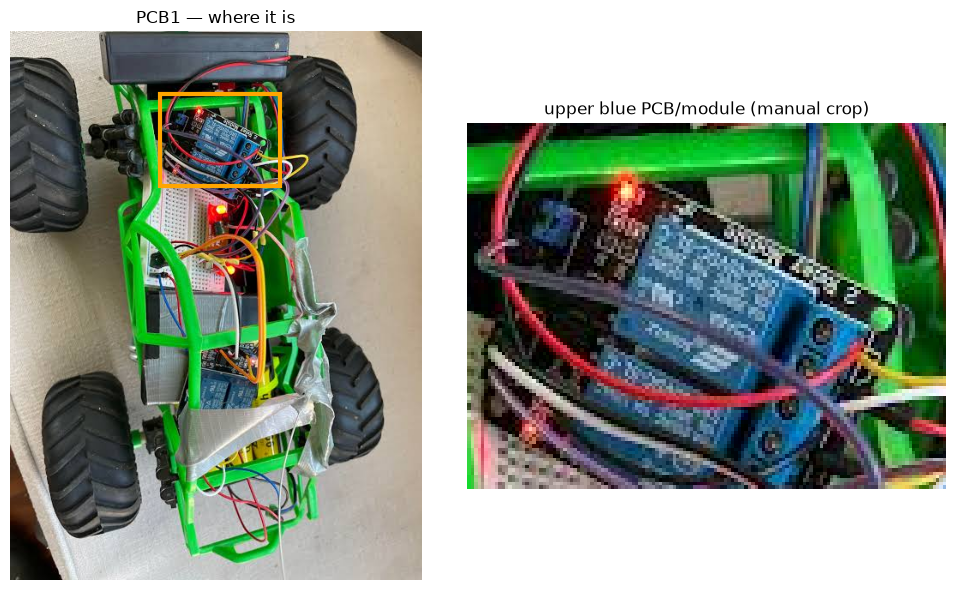

Evidence: visible; exact identity unverified


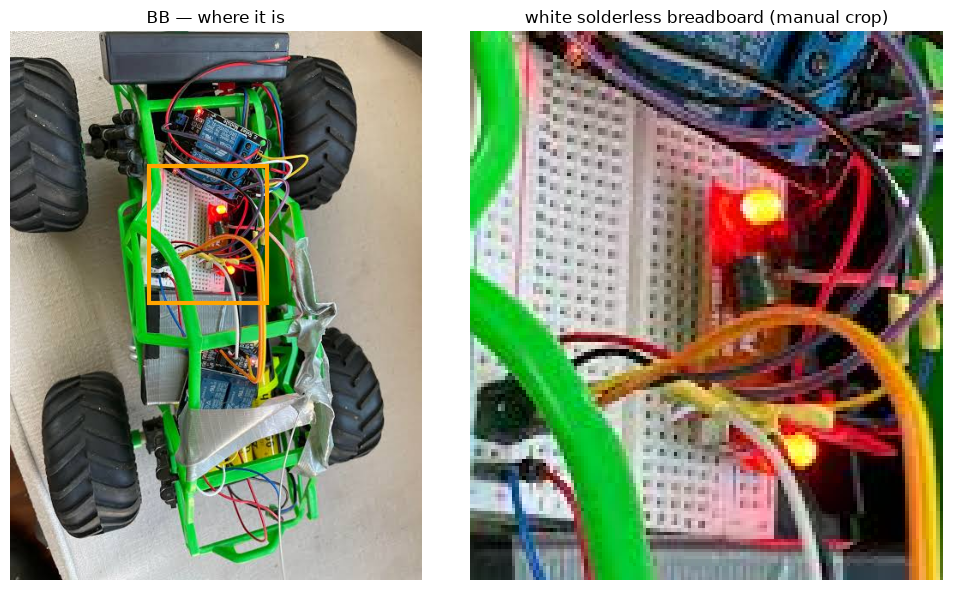

Evidence: visible


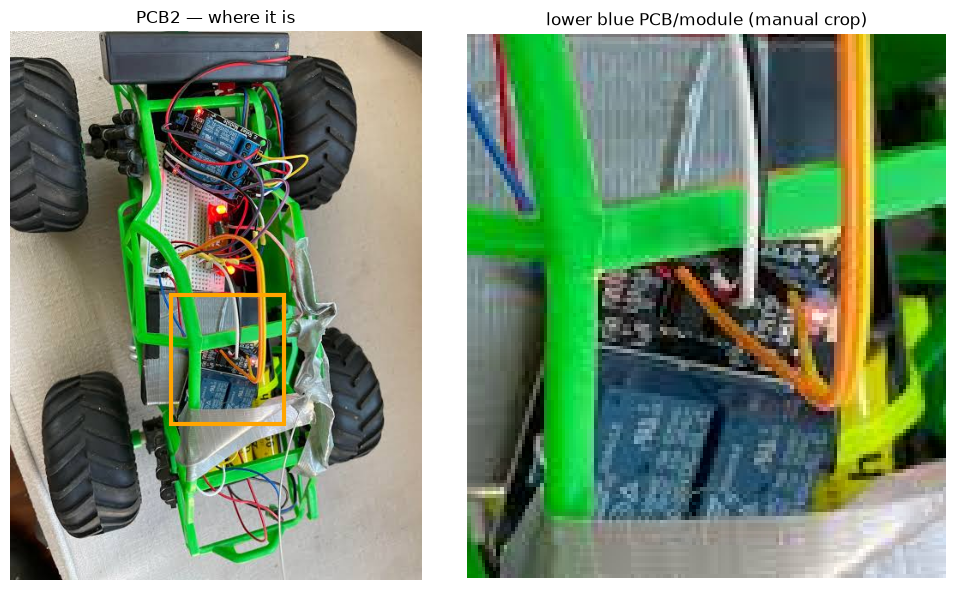

Evidence: visible; exact identity unverified


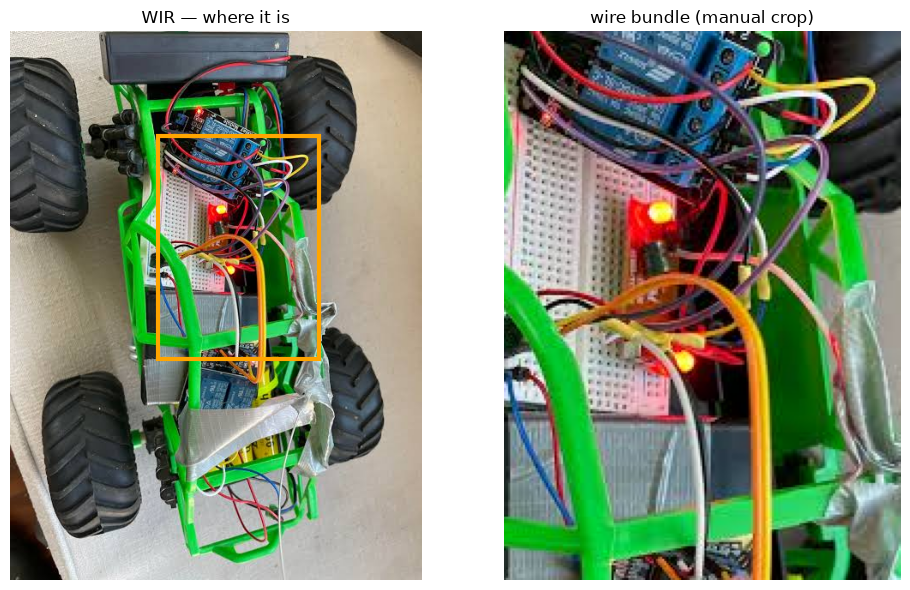

Evidence: visible; count not reliable


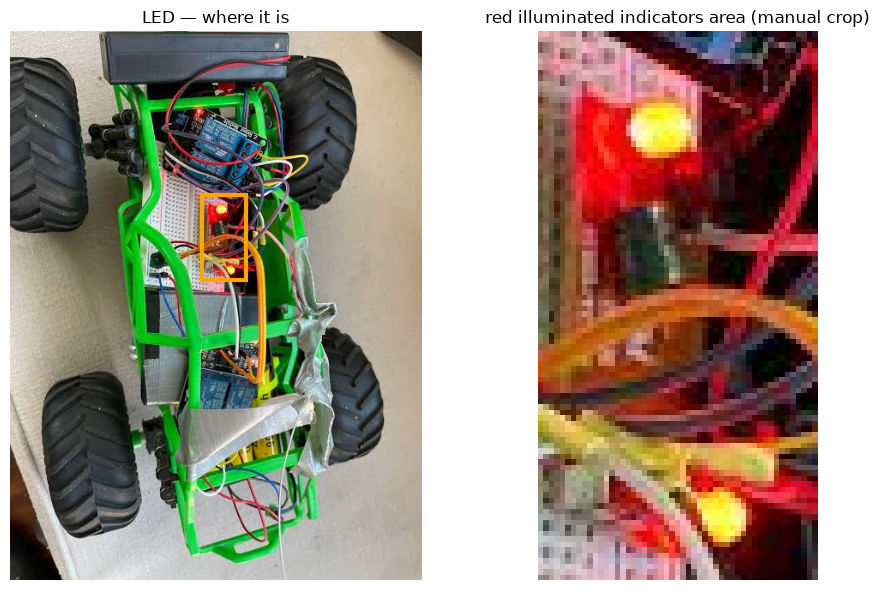

Evidence: visible; at least two lights


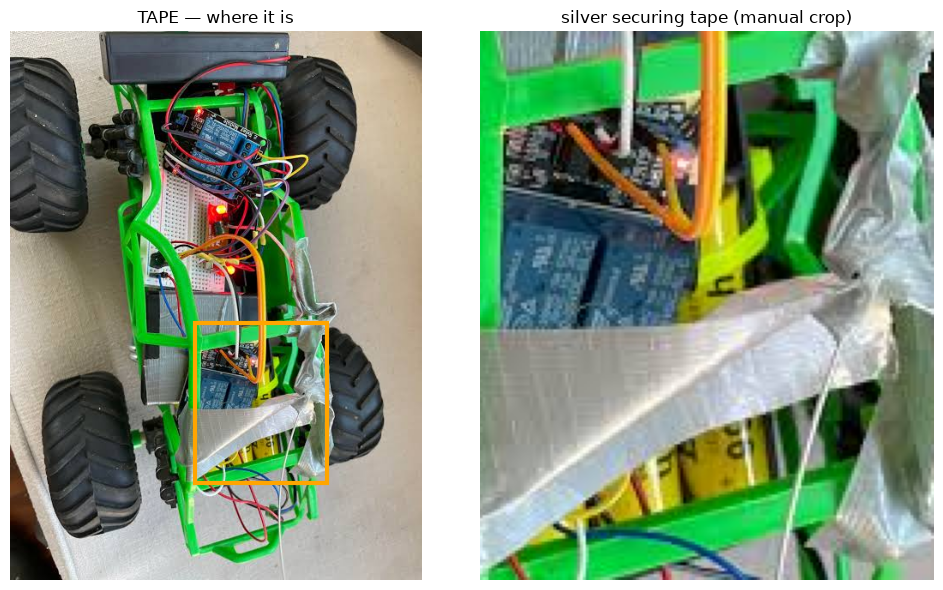

Evidence: visible


In [18]:
# Walk through ALL reference components (one crop per component).
# Change the list to inspect fewer items, e.g. ['PCB1','PCB2','BB'].
for item in reference_parts:
    show_reference(item['id'])

## 3 — Detector text prompts

Grounding DINO is **text-conditioned**: it tries to find regions corresponding to the prompt, but does not guarantee completeness. Use short category phrases. Different phrasings can produce different results. Detect subcomponents with targeted second passes rather than forcing the entire robot into one prompt. Thin wires, tiny LEDs and partially obscured parts are especially challenging.


In [19]:
categories=sorted({str(x.get('category','')).lower().strip() for x in initial['parts'] if x.get('category')})
PROMPT='. '.join(list(dict.fromkeys(categories+['rubber wheel','breadboard','relay module','battery enclosure','green chassis','electric motor','wiring']))[:35])+'.'
BOX_THRESHOLD=0.25; TEXT_THRESHOLD=0.20
print('Text prompts from Mistral:',PROMPT)

Text prompts from Mistral: battery/power enclosure. breadboard. frame/chassis. module. other. tape. wheel. wiring. rubber wheel. relay module. battery enclosure. green chassis. electric motor.


## 4 — Run Grounding DINO (REAL inference)

This section downloads a public pretrained detector on first run. It uses your uploaded image—not the manually estimated boxes. Detection scores are **not calibrated probabilities that the part identity is correct**. Check visually and, if needed, rerun with narrower phrases or lower thresholds.


In [20]:
import torch
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Detector device:', DEVICE)
DINO_MODEL = 'IDEA-Research/grounding-dino-tiny'
dino_detections=[]
if RUN_LOCAL_DETECTION:
    processor = AutoProcessor.from_pretrained(DINO_MODEL)
    detector = AutoModelForZeroShotObjectDetection.from_pretrained(DINO_MODEL).to(DEVICE).eval()
    inputs = processor(images=image, text=PROMPT, return_tensors='pt').to(DEVICE)
    with torch.inference_mode():
        raw_outputs = detector(**inputs)
    processed = processor.post_process_grounded_object_detection(
        raw_outputs,
        inputs.input_ids,
        box_threshold=BOX_THRESHOLD,
        text_threshold=TEXT_THRESHOLD,
        target_sizes=[(H,W)]
    )[0]
    labels = processed.get('text_labels', processed.get('labels', []))
    dino_detections = []
    for idx, (box, score, label) in enumerate(zip(processed['boxes'], processed['scores'], labels), start=1):
        xyxy = [float(v) for v in box.detach().cpu().tolist()]
        dino_detections.append({'id':f'D{idx:03d}', 'label':str(label), 'box_xyxy':xyxy,
                                'dino_score':float(score.detach().cpu()),'source':'grounding_dino',
                                'verified':False})
    print(f'Found {len(dino_detections)} candidate detections')
    pd.DataFrame(dino_detections)

Detector device: cpu


E:\sourcecode\mistral-build-a-bot\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\USER\.cache\huggingface\hub\models--IDEA-Research--grounding-dino-tiny. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to

Found 14 candidate detections


E:\sourcecode\mistral-build-a-bot\.venv\Lib\site-packages\transformers\models\grounding_dino\processing_grounding_dino.py:100: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


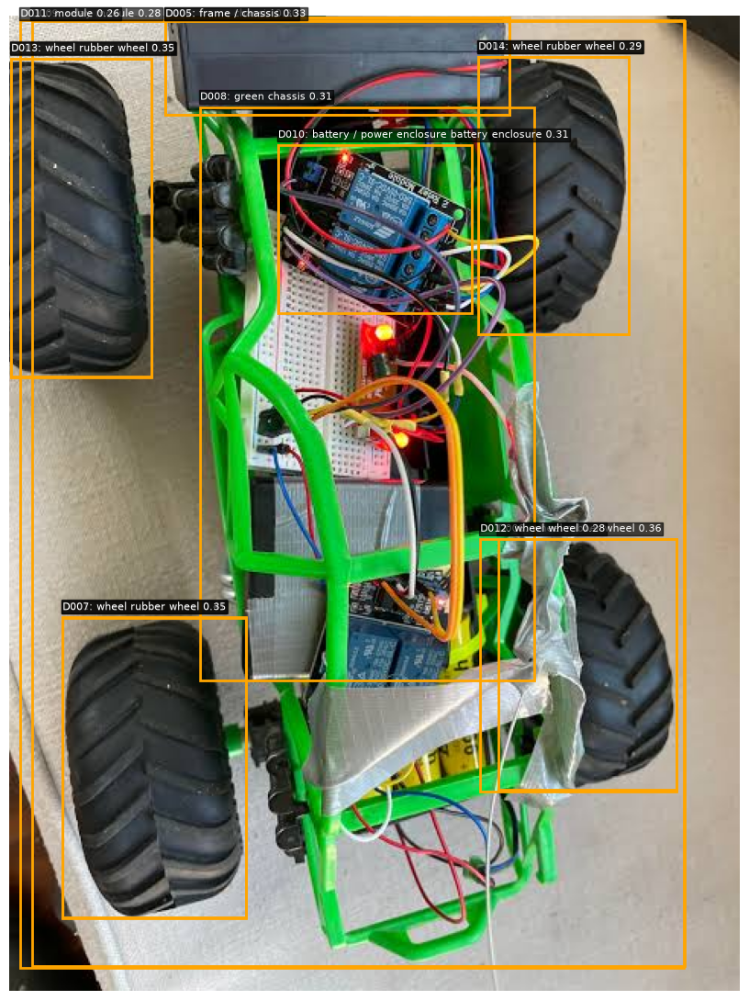

In [21]:
if RUN_LOCAL_DETECTION:
    # Overlay REAL Grounding DINO detection boxes, not the reference boxes.
    fig,ax=plt.subplots(figsize=(9,11)); ax.imshow(image)
    for det in dino_detections:
        x1,y1,x2,y2=det['box_xyxy']
        ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='orange',linewidth=2))
        ax.text(x1,max(0,y1-5),f"{det['id']}: {det['label']} {det['dino_score']:.2f}",
                color='white',fontsize=8,bbox=dict(facecolor='black',alpha=.65,pad=1))
    ax.axis('off');plt.tight_layout()
    fig.savefig(OUTPUT_DIR/'dino_boxes.png',bbox_inches='tight',dpi=160)
    plt.show()

## 5 — Run SAM 2 on each DINO box (REAL segmentation)

SAM 2 produces a pixel mask *conditioned on each DINO box*. The SAM score measures mask quality according to the model, **not whether it is actually the correct component**. The mask may include a neighbouring object when wires and parts overlap.


In [22]:
segmented=[]
if RUN_LOCAL_DETECTION:
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    
    SAM_MODEL = 'facebook/sam2.1-hiera-tiny'
    predictor = SAM2ImagePredictor.from_pretrained(SAM_MODEL, device=DEVICE)
    predictor.set_image(np.array(image))
    
    segmented = []
    for det in dino_detections:
        boxes = np.array(det['box_xyxy'],dtype=np.float32)
        masks, mask_scores, _ = predictor.predict(box=boxes, multimask_output=False)
        mask = masks[0].astype(bool)
        mask_path = OUTPUT_DIR/f"{det['id']}_mask.npy"
        np.save(mask_path, mask)
        segmented.append({**det,'sam_score':float(mask_scores[0]),'mask_path':str(mask_path)})
    print(f'Segmented {len(segmented)} detections')

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
E:\sourcecode\mistral-build-a-bot\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\USER\.cache\huggingface\hub\models--facebook--sam2.1-hiera-tiny. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see thi

Segmented 14 detections


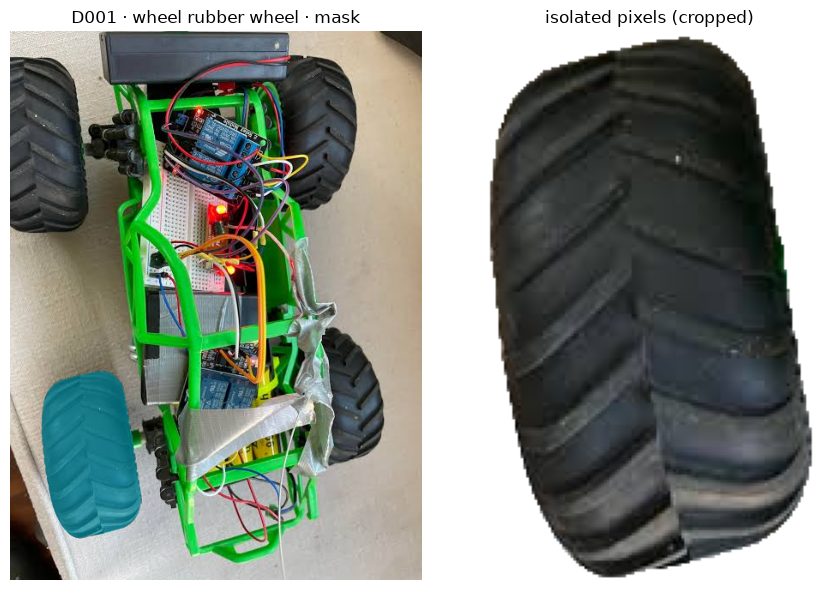

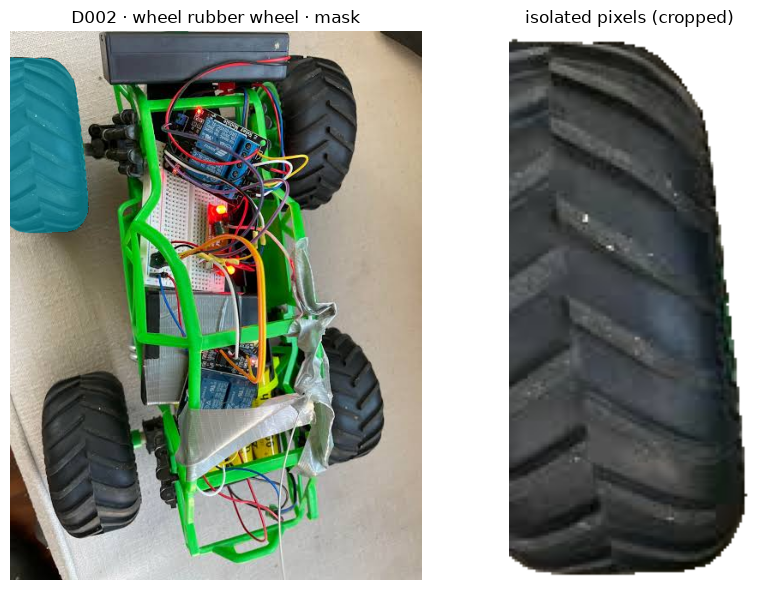

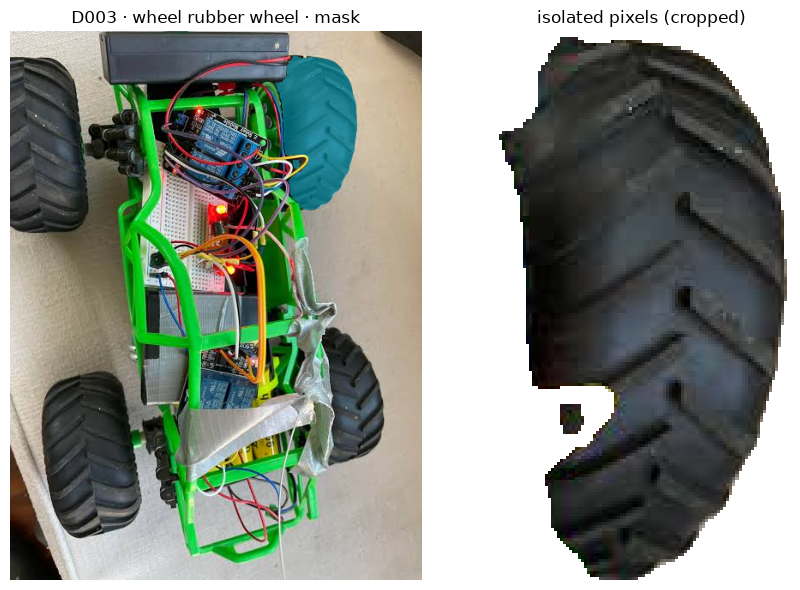

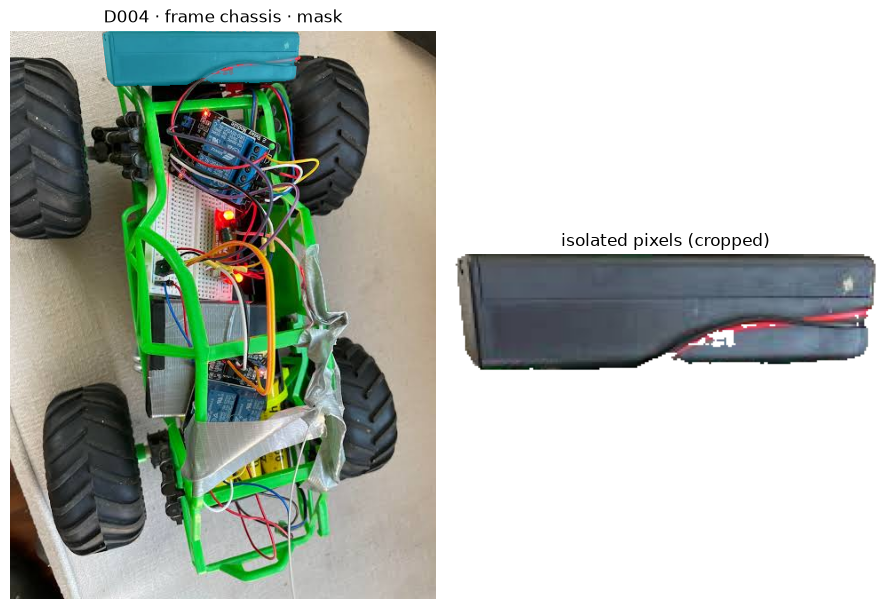

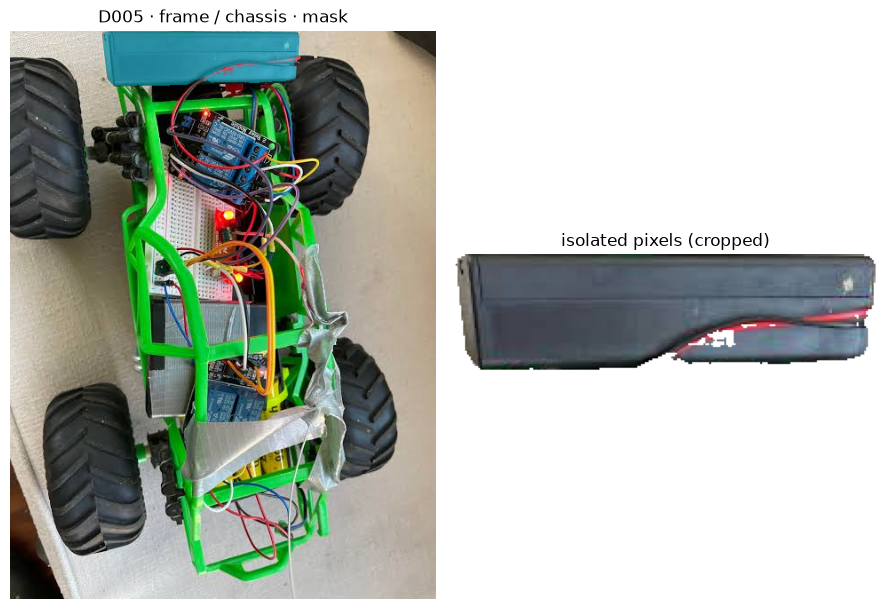

...

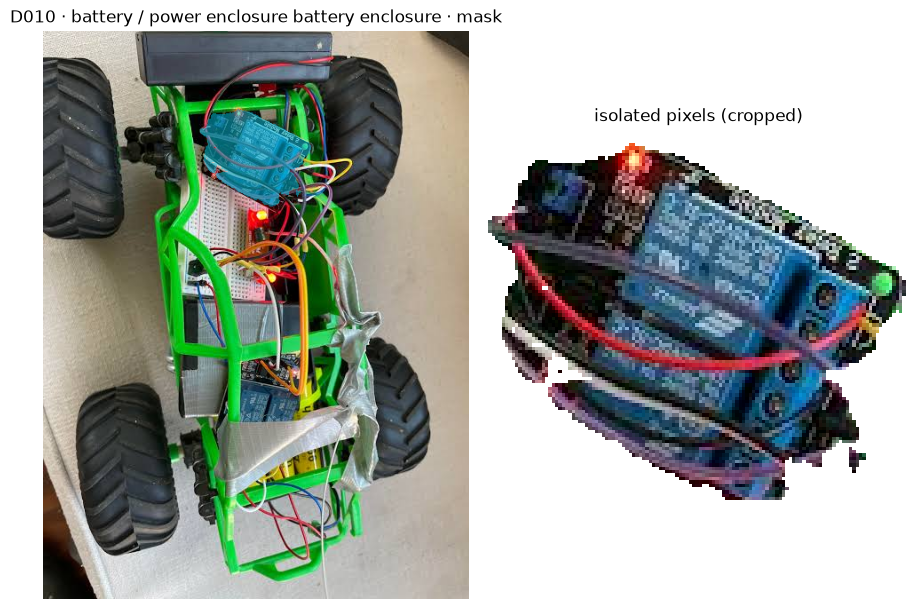

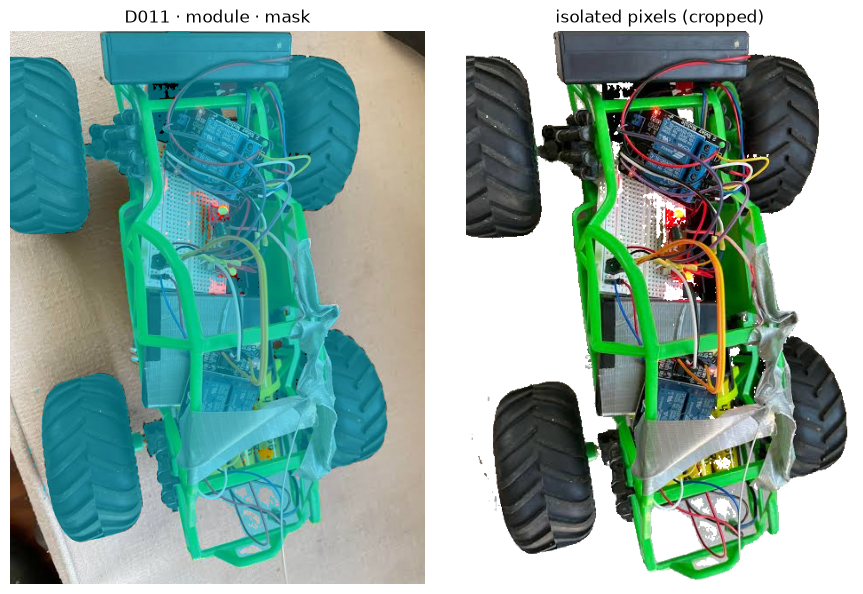

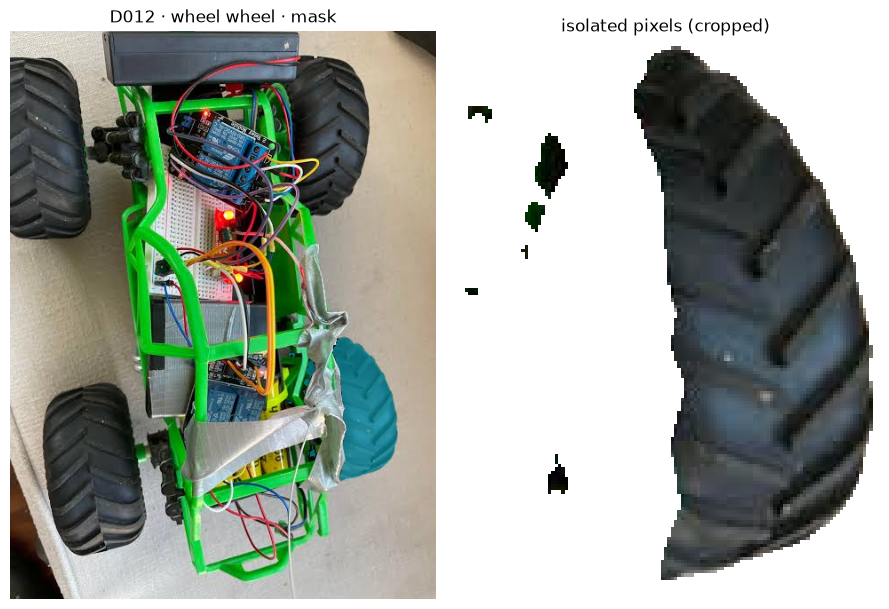

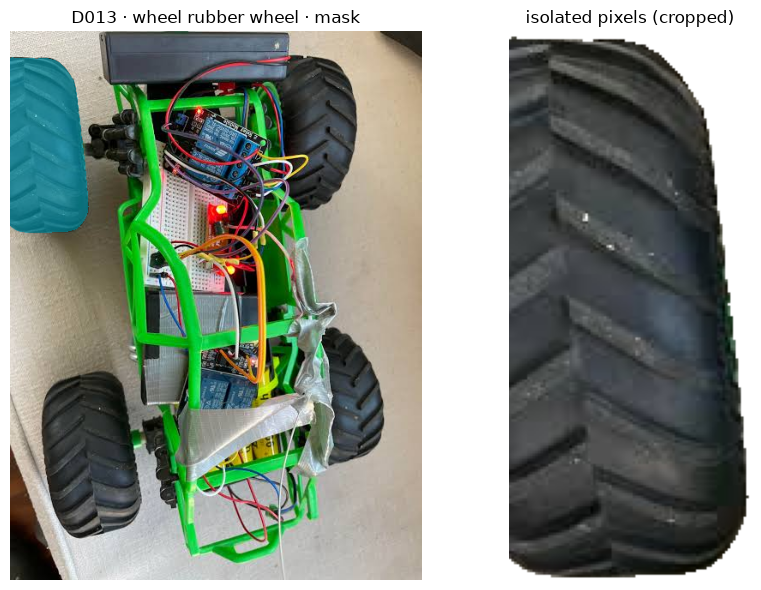

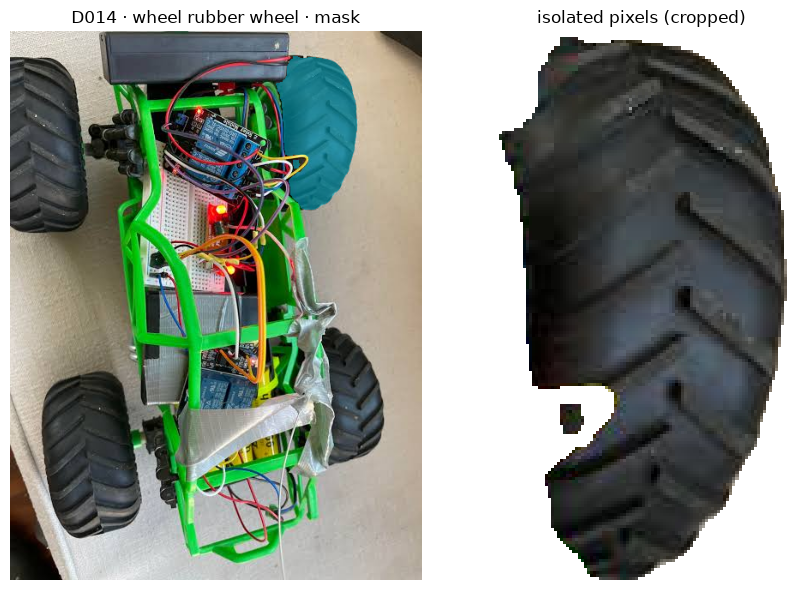

In [23]:
# Display each segmented part as a mask overlay and isolated crop.
from PIL import ImageDraw

def show_segment(det):
    mask=np.load(det['mask_path']).astype(bool)
    arr=np.array(image)
    overlay=arr.copy()
    overlay[mask]=(0.50*overlay[mask]+0.50*np.array([0,195,225])).astype(np.uint8)
    isolated=np.full_like(arr,255)
    isolated[mask]=arr[mask]
    x1,y1,x2,y2=np.round(det['box_xyxy']).astype(int)
    x1,y1=max(x1,0),max(y1,0);x2,y2=min(x2,W),min(y2,H)
    fig,ax=plt.subplots(1,2,figsize=(9,6))
    ax[0].imshow(overlay);ax[0].set_title(f"{det['id']} · {det['label']} · mask")
    ax[1].imshow(isolated[y1:y2,x1:x2]);ax[1].set_title('isolated pixels (cropped)')
    for a in ax: a.axis('off')
    plt.tight_layout();plt.show()

if RUN_LOCAL_DETECTION:
    for det in segmented:
        show_segment(det)

## 6 · Mistral call 2: inspect each component crop

This stage queries Mistral with **the full robot and each detected crop**. Uses SAM/DINO box metadata if available; fallback to manually estimated reference boxes **only if local inference was skipped**. The fallback is not model detection.

D001 wheel rubber wheel dino_sam


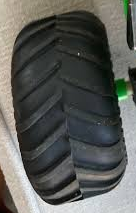

D002 wheel rubber wheel dino_sam


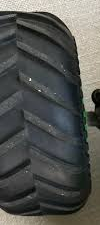

D003 wheel rubber wheel dino_sam


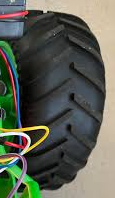

D004 frame chassis dino_sam


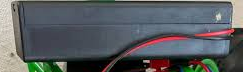

D005 frame / chassis dino_sam


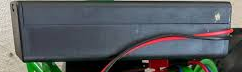

D006 wheel rubber wheel dino_sam


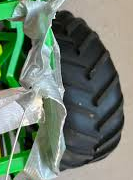

D007 wheel rubber wheel dino_sam


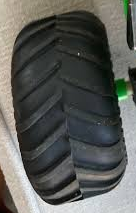

D008 green chassis dino_sam


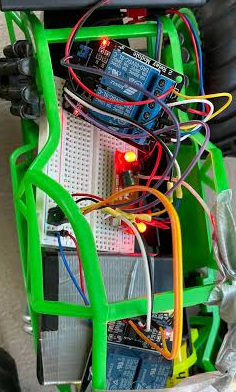

D009 relay module dino_sam


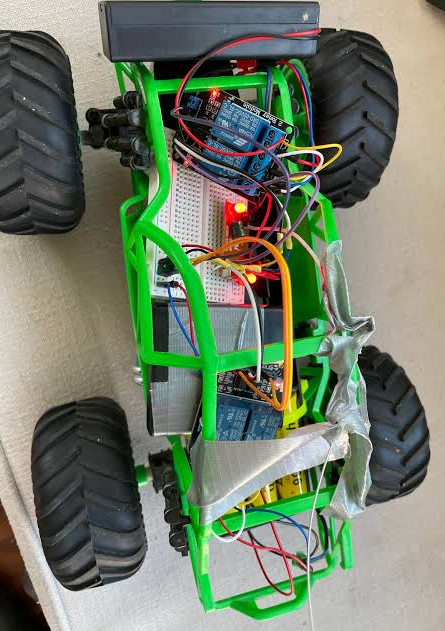

D010 battery / power enclosure battery enclosure dino_sam


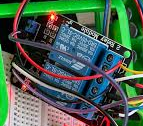

D011 module dino_sam


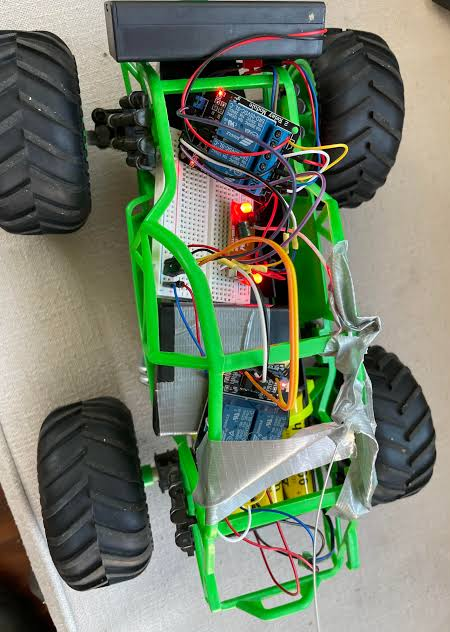

D012 wheel wheel dino_sam


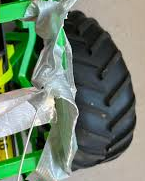

D013 wheel rubber wheel dino_sam


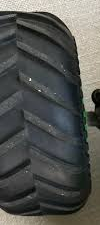

D014 wheel rubber wheel dino_sam


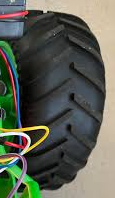

,id,name,category,status,visual_evidence,other_possibilities,confidence,sku,needs_closeup,box_xyxy,origin
0,D001,rubber wheel,wheel,visible_confirmed,[Full robot image shows four black rubber whee...,[Could be solid rubber or foam-filled rather t...,0.95,None,False,"[34.469334, 394.207092, 154.768982, 591.739563]",dino_sam
1,D002,black rubber off-road wheel/tire,wheel,visible_confirmed,[Region crop shows a black rubber tire with de...,[Could be solid rubber or foam-filled rather t...,0.95,None,False,"[0.675884, 27.490797, 92.94223, 236.525238]",dino_sam
2,D003,Rubber Off-Road Wheel,wheel,visible_confirmed,[Region crop clearly shows black rubber tire w...,[Could be foam-filled tire rather than air-fil...,0.92,None,False,"[307.539032, 26.572571, 406.263367, 208.444885]",dino_sam
3,D004,battery pack / power supply housing,power,incorrect_detection,[Black rectangular sealed enclosure mounted on...,"[Hard-case LiPo battery pack, Battery holder w...",0.80,None,True,"[101.916603, 0.590324, 328.007172, 64.613365]",dino_sam
4,D005,battery_pack,power_supply,visible_confirmed,[Black rectangular plastic enclosure mounted a...,"[Battery eliminator circuit (BEC) module, Main...",0.90,None,False,"[102.12291, 0.62881, 328.101837, 64.617325]",dino_sam
5,D006,rubber wheel (knobby tire),wheel,visible_confirmed,[Crop clearly shows a black rubber tire with d...,[Tread pattern could superficially resemble a ...,0.95,None,False,"[320.563873, 343.025787, 437.697968, 507.69635]",dino_sam
6,D007,rubber wheel (off-road tire),wheel,visible_confirmed,[Region crop shows a black rubber tire with de...,[Generic hobby/RC off-road tire; no brand mark...,0.95,None,False,"[34.593742, 394.529968, 154.819351, 591.551514]",dino_sam
7,D008,bright green tubular chassis / roll-cage frame,chassis_frame,visible_confirmed,[Image 1 shows a neon-green plastic tubular fr...,"[Could be confused with green wiring, but no g...",0.95,None,False,"[124.918098, 59.506435, 344.03949, 435.791687]",dino_sam
8,D009,Single-channel electromechanical relay module,relay_module,visible_confirmed,[Blue PCB with black rectangular relay housing...,[Brand and exact model not legible (common for...,0.90,None,True,"[14.31663, 2.668762, 443.217194, 623.49176]",dino_sam
9,D010,"Single-channel relay module (Songle), not a ba...",relay_module,incorrect_detection,[Blue PCB with visible 'SONGLE' silkscreen and...,[Actual battery/power enclosure appears to be ...,0.92,None,True,"[176.135101, 84.424149, 303.583252, 194.734467]",dino_sam


In [24]:
detections_for_review=segmented if 'segmented' in globals() and segmented else []
if detections_for_review:
    candidate_parts=[{'id':str(x.get('id')), 'category':str(x.get('label','unknown')), 'box':x.get('box_xyxy',x.get('bbox_xyxy')), 'origin':'dino_sam'} for x in detections_for_review]
else:
    candidate_parts=[{'id':str(x.get('id')), 'category':str(x.get('name','unknown')), 'box':x.get('bbox'), 'origin':'manual_reference'} for x in reference_parts]

def get_crop(box):
    x1,y1,x2,y2=[int(v) for v in box]; x1=max(0,x1-8); y1=max(0,y1-8); x2=min(W,x2+8); y2=min(H,y2+8)
    return image.crop((x1,y1,x2,y2))
reviews=[]
MAX_CROPS=25
for part in candidate_parts[:MAX_CROPS]:
    if not part['box']:continue
    crop=get_crop(part['box']); print(part['id'],part['category'],part['origin']); display(crop)
    request=f'''Image 1 is full robot, image 2 is region crop for {part['id']} ({part['category']}). Reply ONLY JSON {{"id":"{part['id']}","name":"...","category":"...","status":"visible_confirmed|ambiguous|incorrect_detection","visual_evidence":["..."],"other_possibilities":["..."],"confidence":0.7,"sku":null,"needs_closeup":true}}. Do not claim exact SKU or voltage if n  ot legible. Uncertain is preferable to hallucination.'''
    result=ask_mistral(request,[image,crop],f"02_component_{part['id']}.json")
    result['box_xyxy']=part['box']; result['origin']=part['origin']; reviews.append(result)
(OUT/'02_reviews.json').write_text(json.dumps(reviews,indent=2))
display(pd.DataFrame(reviews))

## 7 · Mistral call 3: mechanical reasoning

Only hypothesise hidden motors, axles, steering joints and connections; do not silently insert them as verified shopping-list items.

In [25]:
mechanics_prompt='Return ONLY JSON with keys "connections" (array of {"from_id":...,"to_id":...,"relation":...,"evidence":"visible|inferred|unknown"}), "possible_missing_parts" (array of {"name":...,"reason":...,"evidence":"inferred"}), "motions" (array of strings), "questions" (array of strings). Consider possible drive motor and steering mechanisms but do NOT assume a motor count, voltage, or unseen chassis construction. Evidence follows:\n'+json.dumps({'initial':initial,'crop_reviews':reviews})[:24000]
mechanics=ask_mistral(mechanics_prompt,[image],'03_mechanical_reasoning.json')
print(json.dumps(mechanics,indent=2))

{
  "connections": [
    {
      "from_id": "P001",
      "to_id": "WIR001",
      "relation": "thick red/black power leads exit battery enclosure and join the multicolored wiring harness",
      "evidence": "visible"
    },
    {
      "from_id": "WIR001",
      "to_id": "B001",
      "relation": "jumper wires route power/signals from harness into the breadboard",
      "evidence": "visible"
    },
    {
      "from_id": "B001",
      "to_id": "M001",
      "relation": "red/black/yellow/white jumpers connect breadboard to the upper blue PCB module (lit red LED)",
      "evidence": "visible"
    },
    {
      "from_id": "B001",
      "to_id": "M002",
      "relation": "wires run from breadboard area down toward the lower blue PCB module; exact endpoints partly obscured by tape/wires",
      "evidence": "visible"
    },
    {
      "from_id": "M001",
      "to_id": "WIR001",
      "relation": "upper module is wired into the harness with multiple colored leads",
      "evidence": "visib

## 8 · Mistral call 4: evidence-based BOM reconciliation

Model checks original photo, initial inventory, detection/crop reviews, and mechanical hypotheses. It may identify uncertain parts but **can't verify online catalogue products without catalogue evidence**. Populate `CATALOGUE` from real supplier API responses if you have them.

In [26]:
CATALOGUE=[]  # Optionally supply real validated supplier search results here
verify_prompt='Return ONLY JSON {"bom":[{"name":"...","category":"...","quantity":4,"evidence":"visible|inferred|unknown","source_ids":["..."],"sku":null,"product_url":null,"review_required":true,"notes":"..."}],"unresolved":["..."]}. Count distinct visible instances, group components sensibly, show unknowns separately. Never invent an SKU, product URL, dimensions, motor count or confirmed hidden part. Inferred components must have review_required=true and may have null quantity. Only use catalogue SKU/URL when supplied as documented candidate. Evidence:\n'+json.dumps({'initial':initial,'detections':detections_for_review,'reviews':reviews,'mechanical':mechanics,'catalogue':CATALOGUE},default=str)[:30000]
proposal=ask_mistral(verify_prompt,[image],'04_bom_proposal.json')
display(pd.DataFrame(proposal.get('bom',[])))

,name,category,quantity,evidence,source_ids,sku,product_url,review_required,notes
0,"off-road rubber wheel/tire (black, chevron tread)",wheel,4.0,visible,"[W001, W002, W003, W004, D001, D002, D003, D00...",None,None,False,Four distinct wheels at the four corners; no b...
1,green tubular frame / roll-cage chassis,frame/chassis,1.0,visible,"[C001, D008]",None,None,False,Rigid neon-green open tubular frame holding el...
2,black rectangular battery/power enclosure,battery/power enclosure,1.0,visible,"[P001, D004, D005]",None,None,True,Sealed black case across the top with thick re...
3,solderless breadboard,breadboard,1.0,visible,[B001],None,None,False,White breadboard in the center with red/yellow...
4,"blue PCB module (likely single-channel relay, ...",relay_module,2.0,visible,"[M001, M002, D009, D010, D011]",None,None,True,Two blue boards; upper has a lit red LED and S...
5,gray rectangular block (function unknown),other,1.0,visible,[O001],None,None,True,Metal-looking block directly beneath the bread...
6,multicolored jumper wire harness,wiring,1.0,visible,[WIR001],None,None,False,"Grouped harness routed across breadboard, modu..."
7,silver duct tape,tape,1.0,visible,[T001],None,None,False,"Wrapped on the right/front frame section, like..."
8,drive motor(s),motor,NaN,inferred,[mechanical.possible_missing_parts],None,None,True,"Four wheels imply drive, but no motor cans, ge..."
9,steering servo / steering linkage,steering,NaN,inferred,[mechanical.possible_missing_parts],None,None,True,"No servo horn, tie rods, or steering knuckles ..."


## 9 · Deterministic validation and export

Final product list keeps observed parts separate from inferred ones. Machine rules flag unsupported claims; no claim of physical or electrical compatibility without validated supplier specifications.

In [27]:
known={str(x.get('id')) for x in initial.get('parts',[])}|{str(x.get('id')) for x in candidate_parts}
allowed_skus={str(x.get('sku')) for x in CATALOGUE}
issues=[]; lines=proposal.get('bom',[])
for row in lines:
    if row.get('quantity') is not None and (not isinstance(row['quantity'],int) or row['quantity']<0):issues.append(f"Invalid quantity: {row.get('name')}")
    if row.get('evidence')=='visible' and not row.get('source_ids'):issues.append(f"No visual source: {row.get('name')}")
    if set(map(str,row.get('source_ids',[])))-known:issues.append(f"Unknown source ID: {row.get('name')}")
    if row.get('sku') and row['sku'] not in allowed_skus:
        issues.append(f"SKU not catalogue-verified: {row['sku']}"); row['sku']=None;row['product_url']=None
    if row.get('evidence')!='visible':row['review_required']=True
visible=[x for x in lines if x.get('evidence')=='visible']; uncertain=[x for x in lines if x.get('evidence')!='visible']
final={'model':MODEL,'visible_bom':visible,'inferred_or_unknown':uncertain,'unresolved':proposal.get('unresolved',[]),'validation_issues':issues}
(OUT/'final_bom.json').write_text(json.dumps(final,indent=2))
pd.DataFrame(lines).to_csv(OUT/'final_bom.csv',index=False)
md_lines=['# Robot BOM','','## Visible parts','']+[f"- {x.get('name')}: {x.get('quantity')} (source IDs: {x.get('source_ids')})" for x in visible]+['','## Inferred / unknown','']+[f"- {x.get('name')} — {x.get('notes','')}" for x in uncertain]+['','## Checks','']+['- '+x for x in issues+proposal.get('unresolved',[])]
(OUT/'final_bom.md').write_text('\n'.join(md_lines),encoding='utf-8')
print('Exported',OUT/'final_bom.json',OUT/'final_bom.csv',OUT/'final_bom.md')
print('Warnings:',issues)

Exported E:\sourcecode\mistral-build-a-bot\test-mistral\mistral_robot_results\final_bom.json E:\sourcecode\mistral-build-a-bot\test-mistral\mistral_robot_results\final_bom.csv E:\sourcecode\mistral-build-a-bot\test-mistral\mistral_robot_results\final_bom.md
Warnings: ['Unknown source ID: drive motor(s)', 'Unknown source ID: steering servo / steering linkage', 'Unknown source ID: motor driver / ESC', 'Unknown source ID: axles / wheel hubs', 'Unknown source ID: battery cells inside enclosure', 'Unknown source ID: main controller / receiver (MCU)', 'Unknown source ID: power switch']


## 10 · What to photograph next

The underside reveals the motor/gearbox and drivetrain. Close-up PCB images reveal controller identities. Side views reveal mounts and axles. Verify voltage/current, dimensions, BOM compatibility and exact supplier SKUs against specifications before buying.

Official docs: [Mistral Vision](https://docs.mistral.ai/inference/conversations/vision), [Grounding DINO](https://github.com/IDEA-Research/GroundingDINO), [SAM 2](https://github.com/facebookresearch/sam2).